In [1]:
import json

train_files = json.load(open("./data/train.json")) 
test_files = json.load(open("./data/test.json"))
val_files = json.load(open("./data/test.json"))


In [2]:
#genearte narrative2id from dataset
narrative2id = {}
for split in [train_files, test_files, val_files]:
    for doc in split:
        narrative = doc["dom_narr"]
        if narrative not in narrative2id:
            narrative2id[narrative] = len(narrative2id)
            
narrative2id

{'CC: Amplifying Climate Fears': 0,
 'CC: Climate change is beneficial': 1,
 'CC: Controversy about green technologies': 2,
 'CC: Criticism of climate movement': 3,
 'CC: Criticism of climate policies': 4,
 'CC: Criticism of institutions and authorities': 5,
 'CC: Downplaying climate change': 6,
 'CC: Green policies are geopolitical instruments': 7,
 'CC: Hidden plots by secret schemes of powerful groups': 8,
 'CC: Questioning the measurements and science': 9,
 'URW: Amplifying war-related fears': 10,
 'URW: Blaming the war on others rather than the invader': 11,
 'URW: Discrediting Ukraine': 12,
 'URW: Discrediting the West, Diplomacy': 13,
 'URW: Distrust towards Media': 14,
 'URW: Hidden plots by secret schemes of powerful groups': 15,
 'URW: Negative Consequences for the West': 16,
 'URW: Overpraising the West': 17,
 'URW: Praise of Russia': 18,
 'URW: Russia is the Victim': 19,
 'URW: Speculating war outcomes': 20}

In [ ]:
from transformers import AutoTokenizer
model_checkpoint = 'google-bert/bert-base-multilingual-cased'
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)


/home/lfc/.myenv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
def cas_to_dataset_stride(
    cas,
    narrative2id,
    doc_id,
    max_length=512,
    stride=128
):
    text = cas["text"]
    narrative = cas["dom_narr"]
    language = cas["language"]

    narrative_label = narrative2id[narrative]

    encoding = tokenizer(
        text,
        max_length=max_length,
        stride=stride,
        truncation=True,
        padding="max_length",
        return_overflowing_tokens=True,
        return_tensors=None
    )

    dataset = []

    for chunk_idx in range(len(encoding["input_ids"])):

        dataset.append({
            "doc_id": doc_id,
            "input_ids": encoding["input_ids"][chunk_idx],
            "attention_mask": encoding["attention_mask"][chunk_idx],
            "labels": narrative_label,
            "language": language
        })

    return dataset

In [5]:
from datasets import Dataset

label2id = {'O': 0, 'B-Evidence': 1, 'I-Evidence': 2}

id2label = {i: label for i, label in enumerate(label2id.keys())}

def generateDataset(files):
    data_list = []
    for file in files:
        data_list = data_list + cas_to_dataset_stride(file, narrative2id, file["doc_id"])
    return Dataset.from_list(data_list)


from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict

train_dataset = generateDataset(train_files)
test_dataset = generateDataset(test_files)
val_dataset = generateDataset(val_files)
print(len(train_dataset), len(test_dataset))

train_dataset

1742 248


Dataset({
    features: ['doc_id', 'input_ids', 'attention_mask', 'labels', 'language'],
    num_rows: 1742
})

In [6]:
from transformers import DataCollatorWithPadding
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [7]:

import evaluate

accuracy = evaluate.load("accuracy")

In [8]:
import numpy as np
from sklearn.metrics import f1_score, accuracy_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1_macro": f1_score(labels, predictions, average="macro"),
        "f1_micro": f1_score(labels, predictions, average="micro"),
        "f1_weighted": f1_score(labels, predictions, average="weighted"),
    }

In [9]:
id2narrative = {i: narrative for i, narrative in enumerate(narrative2id.keys())}

In [10]:
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer

model = AutoModelForSequenceClassification.from_pretrained(
    model_checkpoint, num_labels=len(narrative2id), id2label=id2narrative, label2id=narrative2id
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [15]:



output_model_name = "narrative_stride"
args = TrainingArguments(
    output_model_name,
    report_to="none",
    eval_strategy = "epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8, #16
    per_device_eval_batch_size=8, #16
    num_train_epochs=100,
    weight_decay=0.01,
    save_strategy="epoch",
    load_best_model_at_end=True,      # Load the best model after training
    save_total_limit=1
    #push_to_hub=True,
)

In [16]:
trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

In [19]:
#is cuda available?
import torch
print("CUDA available:", torch.cuda.is_available())


CUDA available: True


In [22]:
trainer.train()

OutOfMemoryError: CUDA out of memory. Tried to allocate 20.00 MiB. GPU 0 has a total capacity of 10.90 GiB of which 5.06 MiB is free. Process 1950469 has 7.85 GiB memory in use. Process 1959740 has 3.04 GiB memory in use. Of the allocated memory 2.83 GiB is allocated by PyTorch, and 54.58 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [78]:
trainer.save_model("my_model_stride_with_narrative_metric_stride")

In [27]:
from transformers import AutoModelForTokenClassification, AutoTokenizer
#load model from "my_model_/checkpoint-epoch-xx"
model_path = "my_model_stride_with_narrative_metric_stride"
model = AutoModelForTokenClassification.from_pretrained(model_path)
tokenizer = AutoTokenizer.from_pretrained(model_path)

In [45]:
trainer = Trainer(
    model,
    args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics_stride
)

/tmp/ipykernel_942/3676826551.py:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


In [35]:
trainer.evaluate(test_dataset)

644 644 118


{'eval_loss': 2.1239120960235596,
 'eval_model_preparation_time': 0.0038,
 'eval_Evidence_precision': 0.12601626016260162,
 'eval_Evidence_recall': 0.13716814159292035,
 'eval_Evidence_f1': 0.1313559322033898,
 'eval_micro_precision': 0.12601626016260162,
 'eval_micro_recall': 0.13716814159292035,
 'eval_micro_f1': 0.1313559322033898,
 'eval_f1': 0.1313559322033898,
 'eval_precision': 0.12601626016260162,
 'eval_recall': 0.13716814159292035,
 'eval_runtime': 15.5823,
 'eval_samples_per_second': 16.108,
 'eval_steps_per_second': 1.027}

In [50]:
results = trainer.evaluate(test_dataset)
results

{'eval_loss': 2.1239120960235596,
 'eval_model_preparation_time': 0.0038,
 'eval_Evidence_precision': 0.12601626016260162,
 'eval_Evidence_recall': 0.13716814159292035,
 'eval_Evidence_f1': 0.1313559322033898,
 'eval_micro_precision': 0.12601626016260162,
 'eval_micro_recall': 0.13716814159292035,
 'eval_micro_f1': 0.1313559322033898,
 'eval_f1': 0.1313559322033898,
 'eval_precision': 0.12601626016260162,
 'eval_recall': 0.13716814159292035,
 'eval_PT_Evidence_precision': 0.13135593220338984,
 'eval_PT_Evidence_recall': 0.14761904761904762,
 'eval_PT_Evidence_f1': 0.1390134529147982,
 'eval_PT_micro_precision': 0.13135593220338984,
 'eval_PT_micro_recall': 0.14761904761904762,
 'eval_PT_micro_f1': 0.1390134529147982,
 'eval_BG_Evidence_precision': 0.07317073170731707,
 'eval_BG_Evidence_recall': 0.04477611940298507,
 'eval_BG_Evidence_f1': 0.05555555555555555,
 'eval_BG_micro_precision': 0.07317073170731707,
 'eval_BG_micro_recall': 0.04477611940298507,
 'eval_BG_micro_f1': 0.055555555

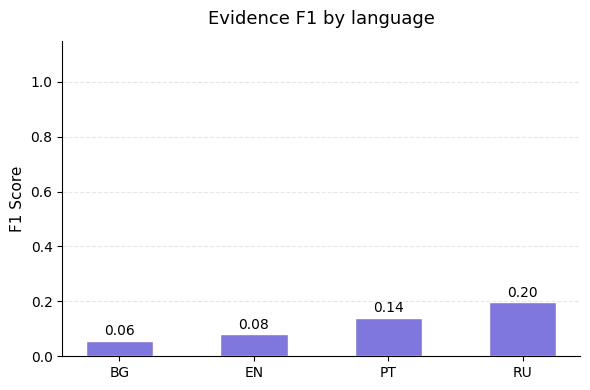

In [52]:
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np

def plot_results_by_language(results):
    cleaned = {k.replace("eval_", ""): v for k, v in results.items()}

    skip = {"loss", "model_preparation_time", "runtime", "samples_per_second",
            "steps_per_second", "f1", "precision", "recall",
            "micro_f1", "micro_precision", "micro_recall",
            "Evidence_f1", "Evidence_precision", "Evidence_recall"}

    by_lang = defaultdict(lambda: defaultdict(dict))
    for key, value in cleaned.items():
        if key in skip:
            continue
        parts = key.split("_")
        if len(parts) >= 3:
            lang = parts[0]
            metric = parts[-1]
            label = "_".join(parts[1:-1])
            by_lang[lang][label][metric] = value

    languages = sorted(by_lang.keys())
    f1_scores = [by_lang[lang].get("Evidence", {}).get("f1", 0) for lang in languages]

    fig, ax = plt.subplots(figsize=(max(6, len(languages) * 1.5), 4))

    bars = ax.bar(languages, f1_scores, color="#7F77DD", edgecolor="white", width=0.5)

    for bar, val in zip(bars, f1_scores):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f"{val:.2f}",
            ha="center", va="bottom", fontsize=10
        )

    ax.set_ylim(0, 1.15)
    ax.set_ylabel("F1 Score", fontsize=11)
    ax.set_title("Evidence F1 by language", fontsize=13, pad=12)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()
    
plot_results_by_language(results)

In [ ]:
from collections import defaultdict

from collections import defaultdict

def evaluate_with_tolerance_per_class(y_true_spans, y_pred_spans, tolerance=5):

    stats = defaultdict(lambda: {"tp": 0, "fp": 0, "fn": 0})

    for doc_true, doc_pred in zip(y_true_spans, y_pred_spans):
        matched_gold = set()

        # Count true positives and false positives
        for p_start, p_end, p_label in doc_pred:
            found_match = False
            for i, (g_start, g_end, g_label) in enumerate(doc_true):
                if i in matched_gold:
                    continue
                if g_label == p_label and abs(p_start - g_start) <= tolerance and abs(p_end - g_end) <= tolerance:
                    stats[p_label]["tp"] += 1
                    matched_gold.add(i)
                    found_match = True
                    break
            if not found_match:
                stats[p_label]["fp"] += 1

        # Count false negatives
        for i, (g_start, g_end, g_label) in enumerate(doc_true):
            if i not in matched_gold:
                stats[g_label]["fn"] += 1

    # Compute per-class precision, recall, F1
    results = {}
    total_tp, total_fp, total_fn = 0, 0, 0
    for label, s in stats.items():
        tp, fp, fn = s["tp"], s["fp"], s["fn"]
        precision = tp / (tp + fp) if tp + fp > 0 else 0
        recall = tp / (tp + fn) if tp + fn > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0
        results[label] = {"precision": precision, "recall": recall, "f1": f1}
        total_tp += tp
        total_fp += fp
        total_fn += fn

    # Micro-averaged metrics
    micro_precision = total_tp / (total_tp + total_fp) if total_tp + total_fp > 0 else 0
    micro_recall = total_tp / (total_tp + total_fn) if total_tp + total_fn > 0 else 0
    micro_f1 = 2 * micro_precision * micro_recall / (micro_precision + micro_recall) if micro_precision + micro_recall > 0 else 0
    results["micro"] = {"precision": micro_precision, "recall": micro_recall, "f1": micro_f1}

    return results





def tokens_to_spans(pred_labels, offset_mapping):
    spans = []
    current_label = None
    start_char = None
    prev_end_char = None

    for (tok_start, tok_end), label in zip(offset_mapping, pred_labels):
        # Skip special tokens or padding
        if tok_start is None or tok_end is None or tok_start == tok_end:
            continue

        # Subword token: extend current span if inside one
        if label == -100:
            if current_label is not None:
                prev_end_char = tok_end
            continue

        if label.startswith("B-"):
            if current_label:
                spans.append((start_char, prev_end_char, current_label))
            current_label = label[2:]
            start_char = tok_start
        elif label.startswith("I-") and current_label == label[2:]:
            prev_end_char = tok_end
        else:  # O or mismatch
            if current_label:
                spans.append((start_char, prev_end_char, current_label))
                current_label = None

        prev_end_char = tok_end

    if current_label:
        spans.append((start_char, prev_end_char, current_label))

    return spans


In [44]:
from collections import defaultdict
import evaluate
metric = evaluate.load("seqeval")
from collections import defaultdict
import torch
import torch.nn.functional as F

def merge_stride_predictions_sequence(predictions, label_map):
    # Step 1: Collect entity spans per document
    doc_entities = defaultdict(list)  # doc_id -> list of (start_char, end_char, label, avg_conf)

    for sample in predictions:
        doc_id = sample["doc_id"]
        offsets = sample["offset_mapping"]
        logits_list = sample["logits"]
        labels = sample["labels"]

        # Convert token-level predictions to entity spans
        current_entity = None  # (start, end, label, sum_conf, token_count)
        for (start, end), logits, t in zip(offsets, logits_list, labels):
            if t == -100:
                continue  # skip subword/special tokens

            probs = F.softmax(torch.tensor(logits), dim=-1)
            best_conf, best_idx = torch.max(probs, dim=-1)
            pred_label = label_map[int(best_idx)]

            if pred_label.startswith("B-"):
                # save previous entity
                if current_entity is not None:
                    s, e, label, conf_sum, count = current_entity
                    avg_conf = conf_sum / count
                    doc_entities[doc_id].append((s, e, label, avg_conf))
                # start new entity
                current_entity = (start, end, pred_label[2:], best_conf.item(), 1)
            elif pred_label.startswith("I-") and current_entity is not None and pred_label[2:] == current_entity[2]:
                # extend current entity
                current_entity = (current_entity[0], end, current_entity[2], current_entity[3] + best_conf.item(), current_entity[4]+1)
            else:
                # O or mismatched I- tag: end current entity if any
                if current_entity is not None:
                    s, e, label, conf_sum, count = current_entity
                    avg_conf = conf_sum / count
                    doc_entities[doc_id].append((s, e, label, avg_conf))
                    current_entity = None
                # O tag is ignored for entity collection

        # flush last entity
        if current_entity is not None:
            s, e, label, conf_sum, count = current_entity
            avg_conf = conf_sum / count
            doc_entities[doc_id].append((s, e, label, avg_conf))
            current_entity = None

    # Step 2: Merge overlapping entities across windows
    merged_entities_per_doc = {}
    for doc_id, spans in doc_entities.items():
        if not spans:
            merged_entities_per_doc[doc_id] = []
            continue

        # Sort by start char
        spans = sorted(spans, key=lambda x: x[0])
        merged = [spans[0]]

        for span in spans[1:]:
            last = merged[-1]
            # If overlapping and same label, merge with longest/highest avg_conf
            if span[0] <= last[1] and span[2] == last[2]:
                new_start = min(last[0], span[0])
                new_end = max(last[1], span[1])
                new_avg_conf = max(last[3], span[3])  # pick higher avg confidence
                merged[-1] = (new_start, new_end, last[2], new_avg_conf)
            else:
                merged.append(span)

        merged_entities_per_doc[doc_id] = merged

    return merged_entities_per_doc



def merge_stride_predictions_confidence(predictions, label_map):

    doc_tokens = defaultdict(dict)  # doc_id -> {token_start: (best_conf, pred_label, true_label)}
    doc_offsets = defaultdict(list) # doc_id -> list of (start_char, end_char)
    doc_lang = {}
    for sample in predictions:
        doc_id = sample["doc_id"]
        doc_lang[doc_id] = sample["language"]
        offsets = sample["offset_mapping"]
        logits_list = sample["logits"]
        labels = sample["labels"]

        for (start, end), logits, t in zip(offsets, logits_list, labels):
            #if t == -100:
            #    continue  # skip subword/special tokens

            probs = F.softmax(torch.tensor(logits), dim=-1)
            best_conf, best_idx = torch.max(probs, dim=-1)
            pred_label = label_map[int(best_idx)]
            #true_label = label_map[int(t)]

            if t == -100:
                true_label = -100  # keep so subwords can extend span later
            else:
                true_label = label_map[int(t)]

            # if token already seen, keep the most confident prediction
            if start in doc_tokens[doc_id]:
                #if best_conf > doc_tokens[doc_id][start][0]:
                #    doc_tokens[doc_id][start] = (best_conf, pred_label, true_label)
                pass
            else:
                doc_tokens[doc_id][start] = (best_conf, pred_label, true_label)
            
            # keep track of document-level offsets
            if start not in [s for s, e in doc_offsets[doc_id]]:
                doc_offsets[doc_id].append((start, end))

    y_true_per_doc = []
    y_pred_per_doc = []

    for doc_id in doc_tokens:
        token_starts = sorted(doc_tokens[doc_id].keys())
        doc_true_labels = []
        doc_pred_labels = []

        for start in token_starts:
            _, pred_label, true_label = doc_tokens[doc_id][start]
            doc_pred_labels.append(pred_label)
            doc_true_labels.append(true_label)

        y_true_per_doc.append(doc_true_labels)
        y_pred_per_doc.append(doc_pred_labels)

        # sort offsets for the document
        doc_offsets[doc_id] = sorted(doc_offsets[doc_id], key=lambda x: x[0])
    return y_true_per_doc, y_pred_per_doc, doc_offsets, doc_lang



from seqeval.metrics import classification_report, f1_score
pred_spans_ner = []
gold_spans_ner = []
def compute_metrics_stride(eval_preds):
    global pred_spans_ner
    global gold_spans_ner
    logits, labels = eval_preds  # logits shape: (batch_size, seq_len, num_labels)
    
    predictions = []
    for i in range(len(logits)):
        predictions.append({
            "doc_id": test_dataset[i]["doc_id"],
            "language": test_dataset[i]["language"], 
            "offset_mapping": test_dataset[i]["offset_mapping"],
            "logits": logits[i],   # store raw logits, not argmax
            "labels": labels[i]
        })

    y_true, y_pred, doc_offsets, doc_lang = merge_stride_predictions_confidence(predictions, model.config.id2label)

    # =====================================================
    # GLOBAL SPANS
    # =====================================================
    all_pred_spans = []
    all_gold_spans = []

    for i, doc_id in enumerate(doc_offsets.keys()):
        pred_spans = tokens_to_spans(y_pred[i], doc_offsets[doc_id])
        gold_spans = tokens_to_spans(y_true[i], doc_offsets[doc_id])
        all_pred_spans.append(pred_spans)
        all_gold_spans.append(gold_spans)

    pred_spans_ner = all_pred_spans
    gold_spans_ner = all_gold_spans

    # =====================================================
    # GLOBAL METRICS
    # =====================================================
    results = evaluate_with_tolerance_per_class(all_gold_spans, all_pred_spans, tolerance=0)

    flat = {}
    for label, scores in results.items():
        for metric_name, value in scores.items():
            flat[f"{label}_{metric_name}"] = value

    flat["f1"] = flat.get("micro_f1", 0.0)
    flat["precision"] = flat.get("micro_precision", 0.0)
    flat["recall"] = flat.get("micro_recall", 0.0)

    # =====================================================
    # PER-LANGUAGE METRICS
    # =====================================================
    lang_pred_spans = defaultdict(list)
    lang_gold_spans = defaultdict(list)

    for i, doc_id in enumerate(doc_offsets.keys()):
        lang = doc_lang[doc_id]
        lang_pred_spans[lang].append(all_pred_spans[i])
        lang_gold_spans[lang].append(all_gold_spans[i])

    for lang in lang_pred_spans:
        lang_results = evaluate_with_tolerance_per_class(
            lang_gold_spans[lang],
            lang_pred_spans[lang],
            tolerance=0
        )
        for label, scores in lang_results.items():
            for metric_name, value in scores.items():
                flat[f"{lang}_{label}_{metric_name}"] = value

    return flat


    

In [23]:
trainer = Trainer(
    model,
    args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics_stride
)

/tmp/ipykernel_24154/3808907123.py:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


In [24]:
trainer.evaluate()

644 644 118


{'eval_loss': 2.1239120960235596,
 'eval_model_preparation_time': 0.0038,
 'eval_Evidence_precision': 0.12601626016260162,
 'eval_Evidence_recall': 0.13716814159292035,
 'eval_Evidence_f1': 0.1313559322033898,
 'eval_micro_precision': 0.12601626016260162,
 'eval_micro_recall': 0.13716814159292035,
 'eval_micro_f1': 0.1313559322033898,
 'eval_f1': 0.1313559322033898,
 'eval_precision': 0.12601626016260162,
 'eval_recall': 0.13716814159292035,
 'eval_runtime': 15.4881,
 'eval_samples_per_second': 16.206,
 'eval_steps_per_second': 1.033}

In [25]:
len(pred_spans_ner), len(gold_spans_ner)

(118, 118)